# DORI v2: how much data comes from DORI vs DCLDE

DORI v2 (`data_raw/DORI/20261022_190549/`, built by `scripts/DORI/build_DORI_annotations_v2.py`) is the DCLDE 2027
annotations plus the DORI / ONC additions. Two versions of it are counted here:
- **full**: `annotations.csv`, everything the build script wrote
- **bgcap10000**: `annotations_bgcap10000.csv`, what the experiments train on -- the same rows minus train Background
  beyond 10 000 per dataset (`scripts/DORI/cap_train_background.py`; val / test untouched), with `splits_bgcap10000.csv`

**Source** = DORI if the `Dataset` starts with "DORI" (ONC, incl. the VENUS Strait of Georgia / Saanich sets), else DCLDE.
Lime Kiln and Tekteksen are DCLDE datasets (SMRU, SIMRES).

Units: **rows** (one per annotation or background window), **files** (unique audio files) and **hours** = summed row
durations. Background windows overlap (5 s windows at a 2.5 s hop for DORI's ONC background), so hours overstate
unique audio for Background; for calls they are the annotated call time.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RUN = "/home/noah/HALLO_encoder_collection/data_raw/DORI/20261022_190549"
COLUMNS = ["uid", "Dataset", "Provider", "Labels", "Duration", "LocalPath"]
# configs/pretraining_comparison/00_base.yaml (= exp_2 / exp_3): what the models actually see
CLASSES_TO_DROP = ["NRKW", "OKW", "KW_und", "SAR"]
CLASS_LABEL_MAP = {"AB": "Background", "UndBio": "Background"}
TEST_HOLDOUT = ["DORI VENUS (Strait of Georgia)", "DORI VENUS (Saanich)", "LimeKiln", "Tekteksen"]
SOURCES = ["DCLDE", "DORI"]
COLORS = {"DCLDE": "#2a78d6", "DORI": "#eb6834"}  # categorical slots 1-2 of the dataviz reference palette


def load(name: str) -> pd.DataFrame:
    d = pd.read_csv(f"{RUN}/{name}", low_memory=False, usecols=COLUMNS)
    d["Dataset"] = d.Dataset.str.strip()  # one 'DORI ' row
    d["source"] = np.where(d.Dataset.str.startswith("DORI"), "DORI", "DCLDE")
    return d


full = load("annotations.csv")
capped = load("annotations_bgcap10000.csv").merge(
    pd.read_csv(f"{RUN}/splits_bgcap10000.csv").rename(columns={"fold_0": "split"}), on="uid", how="left")
print(f"full: {len(full):,} rows   bgcap10000: {len(capped):,} rows ({capped.split.isna().sum()} without a split)")

full: 1,205,034 rows   bgcap10000: 505,686 rows (26322 without a split)


## Overview by source

In [2]:
def overview(d: pd.DataFrame) -> pd.DataFrame:
    is_bg = d.Labels.eq("Background")
    table = d.assign(call=~is_bg, call_s=d.Duration.where(~is_bg), bg_s=d.Duration.where(is_bg)).groupby("source").agg(
        datasets=("Dataset", "nunique"), files=("LocalPath", "nunique"), rows=("uid", "size"),
        call_rows=("call", "sum"), background_rows=("call", lambda s: (~s).sum()),
        call_hours=("call_s", lambda s: s.sum() / 3600), background_hours=("bg_s", lambda s: s.sum() / 3600))
    table.loc["total"] = table.sum()
    table.loc["total", "datasets"] = d.Dataset.nunique()
    table.loc["total", "files"] = d.LocalPath.nunique()
    for col in ["rows", "call_rows", "files"]:
        table[f"{col} %"] = 100 * table[col] / table.loc["total", col]
    return table.round(1)


pd.concat({"full": overview(full), "bgcap10000": overview(capped)})

datasets    files       rows  call_rows  background_rows  \
           source                                                             
full       DCLDE       32.0  13073.0  1180187.0   207509.0         972678.0   
           DORI         3.0   6620.0    24847.0     7146.0          17701.0   
           total       35.0  19693.0  1205034.0   214655.0         990379.0   
bgcap10000 DCLDE       32.0  13073.0   480839.0   207509.0         273330.0   
           DORI         3.0   6620.0    24847.0     7146.0          17701.0   
           total       35.0  19693.0   505686.0   214655.0         291031.0   

                   call_hours  background_hours  rows %  call_rows %  files %  
           source                                                              
full       DCLDE         42.5            1350.9    97.9         96.7     66.4  
           DORI          22.4              24.6     2.1          3.3     33.6  
           total         64.9            1375.5   100.0        100.0    100.0  
bgcap10000 DCLDE         42.5             379.6    95.1         96.7     66.4  
           DORI          22.4              24.6     4.9          3.3     33.6  
           total         64.9             404.2   100.0        100.0    100.0

## Labels by source (full DORI v2, raw `Labels`)

In [3]:
def by_label(d: pd.DataFrame, label_col: str = "Labels") -> pd.DataFrame:
    table = pd.crosstab(d[label_col], d.source).reindex(columns=SOURCES, fill_value=0)
    table["total"] = table.sum(axis=1)
    table["DORI %"] = (100 * table.DORI / table.total).round(1)
    return table.sort_values("total", ascending=False)


by_label(full)

source,DCLDE,DORI,total,DORI %
Labels,,,,
Background,972678,17701,990379,1.8
HW,124977,0,124977,0.0
SRKW,20890,5174,26064,19.9
TKW,12707,1830,14537,12.6
UndBio,11820,0,11820,0.0
AB,11623,1,11624,0.0
NRKW,8266,14,8280,0.2
SAR,8078,0,8078,0.0
KW_und,6450,0,6450,0.0


## What the models see (bgcap10000)

After `classes_to_drop` (NRKW, OKW, KW_und, SAR) and `class_label_map` (AB, UndBio -> Background), split into the
source data (train / val, everything outside the four held-out datasets) and the held-out test datasets.
Rows without an audio file (`LocalPath` empty: 585 DORI + 104 StrGeoN rows) are left out: `cap_train_background.py` gives
them no split and the loader can't read them.

In [4]:
model = capped[~capped.Labels.isin(CLASSES_TO_DROP) & capped.LocalPath.notna()].assign(
    label=lambda d: d.Labels.replace(CLASS_LABEL_MAP),
    part=lambda d: np.where(d.Dataset.isin(TEST_HOLDOUT), "held-out test datasets", "source (" + d.split + ")"))
assert model.split.notna().all()
pd.concat({part: by_label(d, "label") for part, d in model.groupby("part")})

source                              DCLDE   DORI   total  DORI %
                       label                                    
held-out test datasets Background    8084  17702   25786    68.6
                       SRKW          4178   3674    7852    46.8
                       TKW              0   1180    1180   100.0
                       HW             161      0     161     0.0
source (train)         Background  146920      0  146920     0.0
                       HW          105007      0  105007     0.0
                       SRKW         14420    811   15231     5.3
                       TKW          10410    510   10920     4.7
source (val)           Background  141769      0  141769     0.0
                       HW           19807      0   19807     0.0
                       TKW           2290     93    2383     3.9
                       SRKW          2197    151    2348     6.4

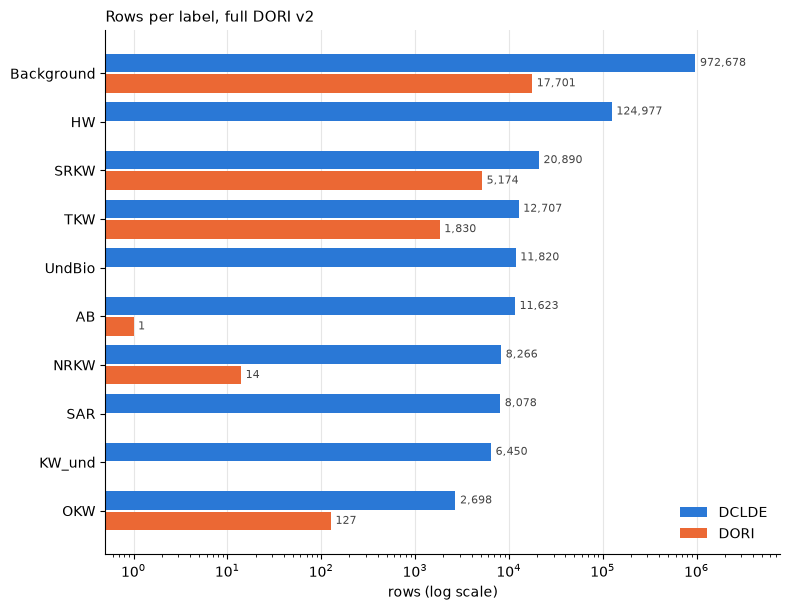

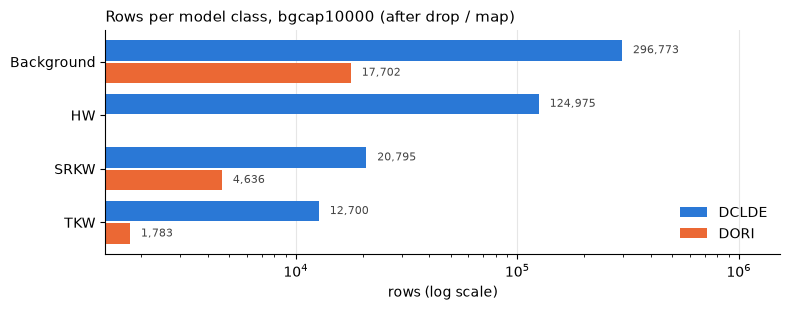

In [5]:
def plot_label_counts(table: pd.DataFrame, title: str):
    labels = table.index[::-1]
    y = np.arange(len(labels))
    height = 0.38
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(labels) + 1.2))
    for i, source in enumerate(SOURCES):
        values = table.loc[labels, source].to_numpy()
        ax.barh(y + (0.5 - i) * (height + 0.04), np.where(values > 0, values, np.nan), height=height,
                color=COLORS[source], label=source)
        for yi, v in zip(y + (0.5 - i) * (height + 0.04), values):
            if v > 0:
                ax.text(v * 1.12, yi, f"{v:,}", va="center", fontsize=8, color="#444")
    ax.set_xscale("log")
    ax.set_yticks(y, labels)
    ax.set_xlabel("rows (log scale)")
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(right=ax.get_xlim()[1] * 4)  # room for the value labels
    ax.legend(frameon=False, loc="lower right")
    fig.tight_layout()
    return fig


plot_label_counts(by_label(full), "Rows per label, full DORI v2")
plot_label_counts(by_label(model, "label"), "Rows per model class, bgcap10000 (after drop / map)")
plt.show()

## Per dataset

In [6]:
per_dataset = (full.pivot_table(index=["source", "Provider", "Dataset"], columns="Labels", values="uid", aggfunc="size", fill_value=0)
               .assign(total=lambda t: t.sum(axis=1)))
per_dataset.insert(0, "files", full.groupby(["source", "Provider", "Dataset"]).LocalPath.nunique())
per_dataset.insert(1, "bgcap10000 rows", capped.groupby(["source", "Provider", "Dataset"]).size())
per_dataset.insert(2, "held out", per_dataset.index.get_level_values("Dataset").isin(TEST_HOLDOUT))
per_dataset.sort_values(["source", "total"], ascending=[True, False])

Labels                                                files  bgcap10000 rows  \
source Provider       Dataset                                                  
DCLDE  DFO_CRP        WVanIsl                          5644           175171   
                      NorthBc                          3730            90456   
       ONC            BarkleyCanyon                    1233            31265   
       JASCO_VFPA     HaroStraitNorth                   143            24978   
                      HaroStraitSouth                   138            23679   
       DFO_WDLP       SwanChan                          271            16662   
       SIO            Cpe_Elz                            46            15582   
       DFO_WDLP       CarmanahPt                        254            12393   
                      StrGeoS2                          166            11836   
       SIO            Quin_Can                           16            10760   
       SIMRES         Tekteksen                         143            10973   
       DFO_WDLP       StrGeoN1                          151            10517   
       UAF_NGOS       Field_HTI                          43             7131   
       OrcaSound      orcasound_lab                     384             6612   
       DFO_WDLP       StrGeoS1                           85             6053   
       JASCO_VFPA     BoundaryPass                        9             4584   
       OrcaSound      bush_point                        194             3510   
       JASCO_VFPA_ONC StraitofGeorgia                    42             3292   
       UAF_NGOS       MS_671879205                       31             2473   
                      Field_SondTrap                      8             2276   
       SMRUConsulting LimeKiln                          148             2186   
       OrcaSound      port_townsend                     109             1923   
       UAF_NGOS       KB_67424266                        23             1826   
       DFO_WDLP       StrGeoN2                           25             1783   
       UAF_NGOS       HE_67424266                        13              949   
                      KB_67383303                         7              740   
                      MS_6897                             4              394   
                      MS_5360                             6              365   
                      HE_67391498                         2              148   
                      RB_335826997                        2              140   
                      KB_5354                             2              106   
                      RB_67424266                         1               76   
DORI   ONC            DORI VENUS (Strait of Georgia)   4932            22552   
                      DORI                             1686             2291   
                      DORI VENUS (Saanich)                4                4   

Labels                                                held out    AB  \
source Provider       Dataset                                          
DCLDE  DFO_CRP        WVanIsl                            False  5076   
                      NorthBc                            False  3463   
       ONC            BarkleyCanyon                      False     0   
       JASCO_VFPA     HaroStraitNorth                    False   473   
                      HaroStraitSouth                    False   384   
       DFO_WDLP       SwanChan                           False   305   
       SIO            Cpe_Elz                            False    47   
       DFO_WDLP       CarmanahPt                         False   263   
                      StrGeoS2                           False   143   
       SIO            Quin_Can                           False    10   
       SIMRES         Tekteksen                           True   419   
       DFO_WDLP       StrGeoN1                           False   148   
       UAF_NGOS       Field_HTI

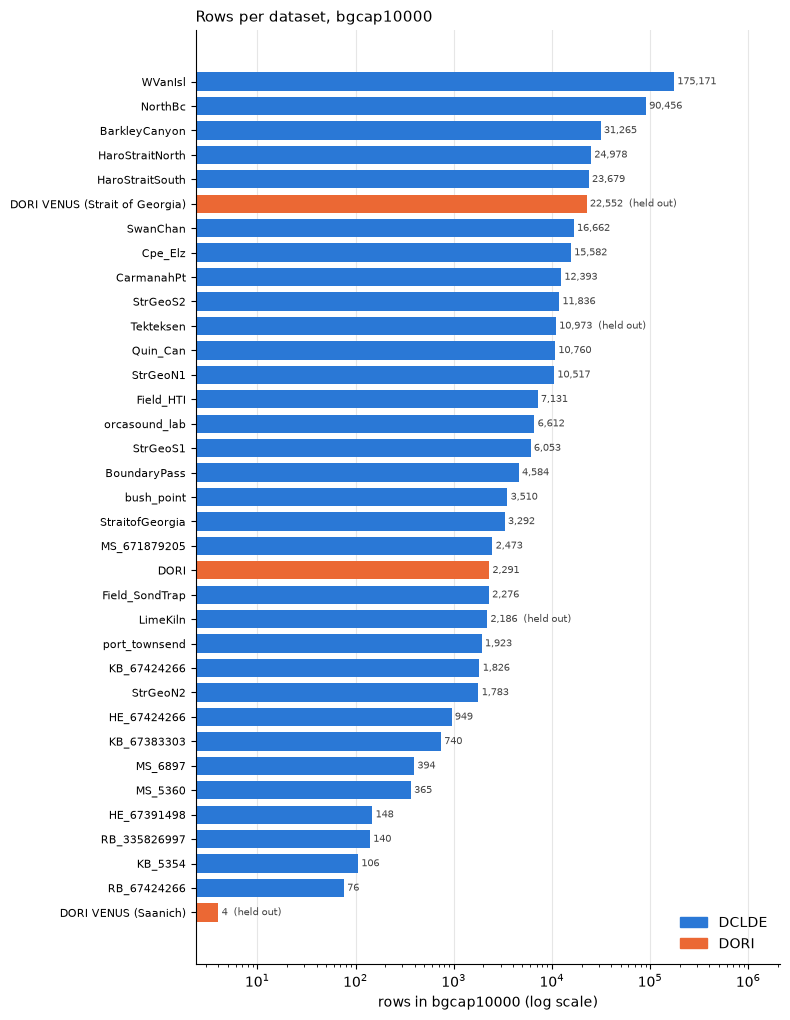

In [7]:
rows = per_dataset["bgcap10000 rows"].droplevel(["source", "Provider"]).sort_values()
source = full.drop_duplicates("Dataset").set_index("Dataset").source
fig, ax = plt.subplots(figsize=(8, 0.26 * len(rows) + 1.2))
ax.barh(rows.index, rows, color=[COLORS[source[d]] for d in rows.index], height=0.75)
for i, (dataset, v) in enumerate(rows.items()):
    ax.text(v * 1.08, i, f"{v:,}" + ("  (held out)" if dataset in TEST_HOLDOUT else ""), va="center", fontsize=7.5, color="#444")
ax.set_xscale("log")
ax.set_xlim(right=rows.max() * 12)
ax.set_xlabel("rows in bgcap10000 (log scale)")
ax.set_title("Rows per dataset, bgcap10000", loc="left", fontsize=11)
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[s]) for s in SOURCES], labels=SOURCES, frameon=False, loc="lower right")
fig.tight_layout()
plt.show()